# Does upstream NW-Pacific IVT/AR intensity have a seasonal cycle that explains why March is a ridge-building-heat "sweet spot"?

**Motivation.** A fresh-eyes review of this project's own numbers raised a two-part hypothesis
about why March specifically produced the record 2026 episode:

> "we are seeing the 'triggering' of melt in different months, but that trigger changes as the
> season progresses. In January, it is practically impossible to trigger widespread snow melt
> or sublimation... April requires only short bursts of warm weather because the snow has
> already been brought to the brink of melting by the seasonal trend. March is in the middle.
> It needs the synoptic scale to prolong the conditions that trigger melt... An interesting
> question could be whether the upstream atmospheric river(s) in March contributed to the heat
> in a substantial way. This could be the unique time of year when that is possible. Earlier in
> the season, ARs are strong and ridging can be strong, but melt is weak; late in the season the
> ARs are weaker and less effective contributors to ridging downstream and high temperatures."

Part 1 (the melt-triggering threshold declining through the season) is already a validated
project finding -- `CA_snowmelt_april_vs_janmar_match_test.ipynb` found the heat-wave/melt
match rate peaks Jan-Mar and drops sharply in April (p=0.0014), and
`CA_t2m_local_heatwave_vs_snowmelt.ipynb` refined this into exactly the stated framing: April
needs only a brief warm pulse, Jan-Mar need a sustained one (the Guo and He 2026 cold-content
mechanism).

**Part 2 -- an AR-ridging "sweet spot" -- is new and genuinely untested.** It splits into two
separable claims, both testable with data already fetched for
`CA_ridging_persistence_drivers_upstream.ipynb` (`upstream_pacific_<year>.nc`, 1990-2025 fit
period + 2026 held out) -- **zero new fetch**:

1. **Does NW-Pacific IVT intensity itself decline seasonally** (strong early, weak late) in
   this project's own upstream source-region box -- not the West Coast landfall region most AR
   climatologies describe?
2. **Does IVT's relationship to CA ridge/warm-episode intensity depend on onset month** -- is
   there a month where the same upstream moisture forcing is more effective at building a
   strong downstream ridge, consistent with a "sweet spot" (not simply monotonic) shape?

**A note on this project's own track record, acted on here rather than discovered after the
fact.** Every upstream-Pacific box-mean diagnostic that skipped an early sensitivity check
later turned out to be a box-placement knife-edge
(`CA_2026_upstream_mechanism_composite.ipynb` Sec. 7, `CA_2026_dynamic_tropopause_diagnosis.ipynb`
Sec. 5, both `*_drivers_waf.ipynb` notebooks, the QRA jet-ratio test in
`CA_ridging_persistence_quasi_resonance.ipynb`). Section 5 below runs a box-sensitivity sweep
on both of this notebook's headline tests from the start, instead of trusting a single baseline
box.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kruskal, mannwhitneyu, percentileofscore
import statsmodels.formula.api as smf

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
YEARS = list(range(1990, 2026))        # fit period, matches every other notebook in this project
CLIM_WINDOW = 5
MIN_DURATION = 5
MAX_GAP = 1
SIGN = 1
THRESHOLD_SD = 1                        # full-sample threshold, matches drivers_upstream.ipynb

N_BOOT = 2000
rng = np.random.default_rng(42)

# Same box CA_ridging_persistence_drivers_upstream.ipynb uses for its onset_ivt_nwpac
# predictor -- Davis's NW Pacific omega-block box -- kept identical here for direct
# comparability with that notebook's results.
NWPAC_LAT, NWPAC_LON = slice(60, 40), slice(140, 180)
DOMAIN_LAT, DOMAIN_LON = slice(65, 15), slice(140, 250)   # full upstream_pacific_*.nc domain


## 2. Does NW-Pacific IVT have a seasonal cycle at all, independent of any ridging event?

Builds the full daily (not event-conditional) NW-Pacific box-mean and whole-domain-mean IVT
series for every Jan-Apr day, 1990-2025, to test the premise directly against this project's
own data: is upstream moisture transport actually stronger early in the season and weaker late,
in the specific NW-Pacific source-region box this project already uses?

Loads each year's `viwve`/`viwvn` once and caches the resulting IVT field (`yearly_ivt`) so
Section 5's box-sensitivity sweep can reuse it with no additional disk reads. Box means use
cos(lat) weighting (`box_mean_series` below) -- a deliberate, minor departure from
`CA_ridging_persistence_drivers_upstream.ipynb`'s own `onset_ivt_nwpac`, which used a plain
unweighted `.mean()` over the same box. The box only spans 40-60N so the two should be close,
but given this project's history with the missing-`cos(lat)` WAF bug, computing it correctly
here rather than reproducing the unweighted shortcut seemed worth the (now noted) inconsistency
between the two notebooks.

To avoid day-level pseudoreplication (consecutive days are highly autocorrelated), every
statistical test below operates on one value per year per month (year-mean IVT, n=36 per
month), not raw daily values -- the same year-as-unit principle this project applies
everywhere else autocorrelation could otherwise inflate confidence.

In [2]:
def box_mean_series(da, lat_slice, lon_slice=slice(None, None)):
    sub = da.sel(latitude=lat_slice, longitude=lon_slice)
    w = np.cos(np.deg2rad(sub.latitude))
    return sub.weighted(w).mean(dim=('latitude', 'longitude'))


def load_year_ivt(year):
    ds = xr.open_dataset(DATA_DIR / f'upstream_pacific_{year}.nc', engine='netcdf4')
    ds = ds[['viwve', 'viwvn']]
    ivt = np.sqrt(ds.viwve**2 + ds.viwvn**2)
    return ivt.load()


yearly_ivt = {y: load_year_ivt(y) for y in YEARS}
print(f'Loaded IVT for {len(yearly_ivt)} years ({min(YEARS)}-{max(YEARS)}), '
      f'{yearly_ivt[YEARS[0]].sizes["time"]} days/year')


Loaded IVT for 36 years (1990-2025), 120 days/year


In [3]:
rows = []
for y, da in yearly_ivt.items():
    nwpac = box_mean_series(da, NWPAC_LAT, NWPAC_LON)
    domain = box_mean_series(da, DOMAIN_LAT, DOMAIN_LON)
    idx = pd.to_datetime(da.time.values)
    rows.append(pd.DataFrame({'ivt_nwpac': nwpac.values, 'ivt_domain': domain.values}, index=idx))
daily = pd.concat(rows).sort_index()
daily['year'] = daily.index.year
daily['month'] = daily.index.month
print(f'{len(daily)} total days, {daily.year.nunique()} years')
daily.groupby('month')[['ivt_nwpac', 'ivt_domain']].agg(['mean', 'std'])


4329 total days, 36 years


ivt_nwpac             ivt_domain           
             mean        std        mean        std
month                                              
1       70.562028  27.934458  163.934278  21.114372
2       74.476989  31.235777  153.950957  18.783353
3       91.765273  37.220161  148.301580  18.340589
4      116.031105  42.422815  155.119175  18.678649

In [4]:
year_month_mean = daily.groupby(['year', 'month'])[['ivt_nwpac', 'ivt_domain']].mean().reset_index()
MONTH_NAME = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr'}


def year_block_bootstrap_ci(df, col, month, n_boot=N_BOOT, rng=rng):
    """Resample YEARS with replacement (not days), matching
    ca_blocking_lib.bootstrap_climatology_std's year-block convention."""
    years = df.year.unique()
    sub = df[df.month == month].set_index('year')[col]
    boot = np.array([sub.reindex(rng.choice(years, size=len(years), replace=True)).mean()
                      for _ in range(n_boot)])
    return np.percentile(boot, [5, 95])


seasonal_cycle_results = {}
for col in ['ivt_nwpac', 'ivt_domain']:
    print(f'=== {col}: year-mean IVT by month (n=36 years each), 90% year-block bootstrap CI ===')
    for m in [1, 2, 3, 4]:
        vals = year_month_mean[year_month_mean.month == m][col]
        lo, hi = year_block_bootstrap_ci(year_month_mean, col, m)
        print(f'  {MONTH_NAME[m]}: mean={vals.mean():.1f} kg/m/s, 90% CI=[{lo:.1f}, {hi:.1f}]')

    groups = [year_month_mean[year_month_mean.month == m][col] for m in [1, 2, 3, 4]]
    h, p_kw = kruskal(*groups)
    print(f'  Kruskal-Wallis across all 4 months: H={h:.2f}, p={p_kw:.4f}')

    pair_p = {}
    for a, b in [(1, 2), (2, 3), (3, 4), (1, 4), (1, 3), (2, 4)]:
        ua = year_month_mean[year_month_mean.month == a][col]
        ub = year_month_mean[year_month_mean.month == b][col]
        u, p_mw = mannwhitneyu(ua, ub)
        pair_p[(a, b)] = p_mw
        print(f'  Mann-Whitney {MONTH_NAME[a]} vs {MONTH_NAME[b]}: p={p_mw:.4f}')
    seasonal_cycle_results[col] = {'kruskal_p': p_kw, 'pairwise_p': pair_p}
    print()


=== ivt_nwpac: year-mean IVT by month (n=36 years each), 90% year-block bootstrap CI ===
  Jan: mean=70.6 kg/m/s, 90% CI=[68.1, 73.0]


  Feb: mean=74.5 kg/m/s, 90% CI=[71.1, 77.9]


  Mar: mean=91.8 kg/m/s, 90% CI=[87.9, 95.7]
  Apr: mean=116.0 kg/m/s, 90% CI=[111.5, 120.5]
  Kruskal-Wallis across all 4 months: H=90.45, p=0.0000
  Mann-Whitney Jan vs Feb: p=0.3244
  Mann-Whitney Feb vs Mar: p=0.0000
  Mann-Whitney Mar vs Apr: p=0.0000
  Mann-Whitney Jan vs Apr: p=0.0000
  Mann-Whitney Jan vs Mar: p=0.0000
  Mann-Whitney Feb vs Apr: p=0.0000

=== ivt_domain: year-mean IVT by month (n=36 years each), 90% year-block bootstrap CI ===
  Jan: mean=163.9 kg/m/s, 90% CI=[161.8, 166.0]
  Feb: mean=153.9 kg/m/s, 90% CI=[151.4, 156.3]


  Mar: mean=148.3 kg/m/s, 90% CI=[146.4, 150.2]
  Apr: mean=155.1 kg/m/s, 90% CI=[153.3, 157.0]
  Kruskal-Wallis across all 4 months: H=50.55, p=0.0000
  Mann-Whitney Jan vs Feb: p=0.0000
  Mann-Whitney Feb vs Mar: p=0.0091
  Mann-Whitney Mar vs Apr: p=0.0002
  Mann-Whitney Jan vs Apr: p=0.0000
  Mann-Whitney Jan vs Mar: p=0.0000
  Mann-Whitney Feb vs Apr: p=0.8174



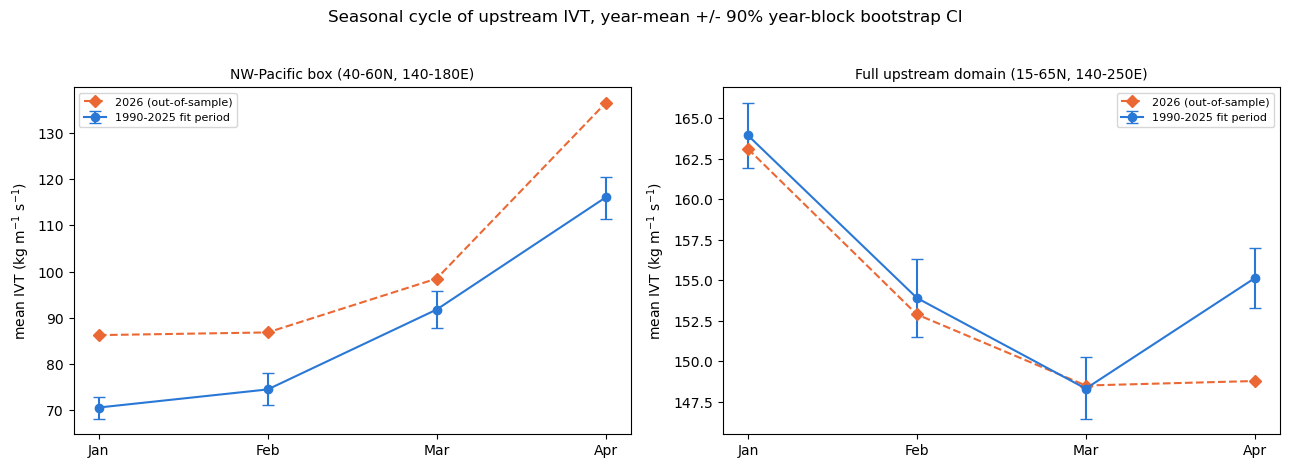

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, title in zip(axes, ['ivt_nwpac', 'ivt_domain'],
                           ['NW-Pacific box (40-60N, 140-180E)', 'Full upstream domain (15-65N, 140-250E)']):
    means, los, his = [], [], []
    for m in [1, 2, 3, 4]:
        vals = year_month_mean[year_month_mean.month == m][col]
        lo, hi = year_block_bootstrap_ci(year_month_mean, col, m)
        means.append(vals.mean()); los.append(vals.mean() - lo); his.append(hi - vals.mean())
    ax.errorbar([1, 2, 3, 4], means, yerr=[los, his], fmt='o-', capsize=4, color='#2a78d6',
                label='1990-2025 fit period')

    ivt_26 = load_year_ivt(2026)
    da26 = box_mean_series(ivt_26, NWPAC_LAT if col == 'ivt_nwpac' else DOMAIN_LAT,
                            NWPAC_LON if col == 'ivt_nwpac' else DOMAIN_LON)
    df26 = pd.DataFrame({'v': da26.values}, index=pd.to_datetime(ivt_26.time.values))
    df26['month'] = df26.index.month
    means_26 = [df26[df26.month == m].v.mean() for m in [1, 2, 3, 4]]
    ax.plot([1, 2, 3, 4], means_26, 'D--', color='#eb6834', label='2026 (out-of-sample)')

    ax.set_xticks([1, 2, 3, 4]); ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr'])
    ax.set_ylabel('mean IVT (kg m$^{-1}$ s$^{-1}$)')
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
plt.suptitle('Seasonal cycle of upstream IVT, year-mean +/- 90% year-block bootstrap CI', y=1.03)
plt.tight_layout()
plt.show()


## 3. Event-level: does onset-window IVT depend on month, and does its relationship to ridge/warm-episode intensity?

In [6]:
events = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_detrended_mindur5.csv',
                     parse_dates=['start_date', 'end_date'])
events['start_date'] = events.start_date.dt.date
events['end_date'] = events.end_date.dt.date
events = events[events.threshold_sd == THRESHOLD_SD].reset_index(drop=True)
events['onset_month'] = pd.to_datetime(events.start_date).dt.month


def box_window_mean(series, start, end):
    window = series.loc[str(start):str(end)]
    return float(window.mean()) if len(window) else np.nan


events['onset_ivt_nwpac'] = [
    box_window_mean(daily['ivt_nwpac'], row.start_date, pd.Timestamp(row.start_date) + pd.Timedelta(days=4))
    for row in events.itertuples()
]

VAR_LABEL = {'500 hPa height (ridging)': 'Z500', '700 hPa temperature (warm)': 'T700'}
print(f'{len(events)} events at >= {THRESHOLD_SD} sigma:')
print(events.groupby('variable').size())
print('\nEvents per onset month:')
print(events.groupby(['variable', 'onset_month']).size().unstack(fill_value=0))


95 events at >= 1 sigma:
variable
500 hPa height (ridging)      48
700 hPa temperature (warm)    47
dtype: int64

Events per onset month:
onset_month                  1   2   3   4
variable                                  
500 hPa height (ridging)    15  10  13  10
700 hPa temperature (warm)  11  11  13  12


**n per onset month is small (roughly 10-15 events per month per variable) -- every test in this
section is explicitly flagged for that, matching this project's own established caution about
month-level splits elsewhere (decade/month splits "flagged ... as underpowered", n=6-24,
README).**

In [7]:
for var, lbl in VAR_LABEL.items():
    sub = events[events.variable == var].dropna(subset=['onset_ivt_nwpac'])
    print(f'--- {lbl} (n={len(sub)}): onset-window NW-Pac IVT by onset month ---')
    print(sub.groupby('onset_month').onset_ivt_nwpac.agg(['count', 'mean', 'std']))
    groups = [g.onset_ivt_nwpac.values for _, g in sub.groupby('onset_month') if len(g) >= 3]
    if len(groups) >= 2:
        h, p = kruskal(*groups)
        print(f'Kruskal-Wallis across onset months: H={h:.2f}, p={p:.4f}')
    rho, p_rho = spearmanr(sub.onset_month, sub.onset_ivt_nwpac)
    print(f'Spearman (onset month, ordinal) vs onset-window IVT: rho={rho:.2f}, p={p_rho:.4f}\n')


--- Z500 (n=48): onset-window NW-Pac IVT by onset month ---
             count        mean        std
onset_month                              
1               15   67.568959  18.553331
2               10   71.372548  17.531812
3               13   90.181806  29.761867
4               10  116.856270  20.842682
Kruskal-Wallis across onset months: H=19.62, p=0.0002
Spearman (onset month, ordinal) vs onset-window IVT: rho=0.61, p=0.0000

--- T700 (n=47): onset-window NW-Pac IVT by onset month ---
             count        mean        std
onset_month                              
1               11   67.812733  24.058718
2               11   61.437254  14.893375
3               13   95.484207  26.172929
4               12  115.192379  18.725924
Kruskal-Wallis across onset months: H=25.05, p=0.0000
Spearman (onset month, ordinal) vs onset-window IVT: rho=0.68, p=0.0000



### Does onset IVT predict event peak intensity -- pooled, then split by season

`CA_ridging_persistence_drivers_upstream.ipynb` already tested onset-window NW-Pac IVT against
event *duration* (one of its five null-for-Z500 predictors). The hypothesis under test here is
about *heat/ridge intensity*, not duration -- a genuinely different, not-yet-tested
comparison.

In [8]:
print('Pooled (all months together): onset-window IVT vs. event peak intensity (peak_sanom)\n')
for var, lbl in VAR_LABEL.items():
    sub = events[events.variable == var].dropna(subset=['onset_ivt_nwpac', 'peak_sanom'])
    rho, p = spearmanr(sub.onset_ivt_nwpac, sub.peak_sanom)
    print(f'{lbl} (n={len(sub)}): rho={rho:.2f}, p={p:.4f}')


Pooled (all months together): onset-window IVT vs. event peak intensity (peak_sanom)

Z500 (n=48): rho=-0.00, p=0.9749
T700 (n=47): rho=-0.04, p=0.7782


In [9]:
print('Linear interaction model: peak_sanom ~ ivt_c * month_c (month as a continuous, centered '
      'ordinal -- tests whether the IVT-intensity slope trends up or down across the season; '
      'cannot by itself detect a non-monotonic "sweet spot" shape, which the binned test below '
      'checks separately)\n')
interaction_models = {}
for var, lbl in VAR_LABEL.items():
    sub = events[events.variable == var].dropna(subset=['onset_ivt_nwpac', 'peak_sanom']).copy()
    sub['ivt_c'] = sub.onset_ivt_nwpac - sub.onset_ivt_nwpac.mean()
    sub['month_c'] = sub.onset_month - sub.onset_month.mean()
    model = smf.ols('peak_sanom ~ ivt_c * month_c', data=sub).fit()
    interaction_models[lbl] = model
    print(f'=== {lbl} (n={len(sub)}) ===')
    print(model.summary().tables[1])
    print()


Linear interaction model: peak_sanom ~ ivt_c * month_c (month as a continuous, centered ordinal -- tests whether the IVT-intensity slope trends up or down across the season; cannot by itself detect a non-monotonic "sweet spot" shape, which the binned test below checks separately)

=== Z500 (n=48) ===
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         1.7706      0.039     45.070      0.000       1.691       1.850
ivt_c            -0.0029      0.001     -1.956      0.057      -0.006    8.88e-05
month_c           0.0912      0.036      2.562      0.014       0.019       0.163
ivt_c:month_c     0.0011      0.001      0.975      0.335      -0.001       0.004

=== T700 (n=47) ===
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         1.8

In [10]:
print('Binned, descriptive test of a non-monotonic "sweet spot" shape (each bin n~10-15, '
      'explicitly underpowered -- reported as a direct shape check, not a confirmatory test):\n')
for var, lbl in VAR_LABEL.items():
    sub = events[events.variable == var].dropna(subset=['onset_ivt_nwpac', 'peak_sanom'])
    bins = {'Jan (early)': sub.onset_month == 1,
            'Feb-Mar (mid)': sub.onset_month.isin([2, 3]),
            'Apr (late)': sub.onset_month == 4}
    print(f'--- {lbl} ---')
    for name, mask in bins.items():
        g = sub[mask]
        if len(g) >= 5:
            rho, p = spearmanr(g.onset_ivt_nwpac, g.peak_sanom)
            print(f'  {name} (n={len(g)}): rho={rho:.2f}, p={p:.3f}')
        else:
            print(f'  {name} (n={len(g)}): too few events for a correlation')
    print()


Binned, descriptive test of a non-monotonic "sweet spot" shape (each bin n~10-15, explicitly underpowered -- reported as a direct shape check, not a confirmatory test):

--- Z500 ---
  Jan (early) (n=15): rho=-0.42, p=0.121
  Feb-Mar (mid) (n=23): rho=-0.14, p=0.523
  Apr (late) (n=10): rho=-0.05, p=0.881

--- T700 ---
  Jan (early) (n=11): rho=0.19, p=0.574
  Feb-Mar (mid) (n=24): rho=-0.01, p=0.974
  Apr (late) (n=12): rho=-0.24, p=0.443



## 4. Box-sensitivity sweep of both headline tests

Reuses `yearly_ivt` (already loaded, no new disk reads) to recompute both the seasonal-cycle
test (Section 2) and the pooled IVT-vs-peak-intensity test (Section 3) at 6 alternative
NW-Pacific box placements, staying within the fetched domain (15-65N, 140-250E can't be
extended west of 140E).

In [11]:
BOX_VARIANTS = {
    'baseline (40-60N, 140-180E)': (slice(60, 40), slice(140, 180)),
    'north +5 (40-65N)': (slice(65, 40), slice(140, 180)),
    'south +5, narrower (45-60N)': (slice(60, 45), slice(140, 180)),
    'south -5, wider (35-60N)': (slice(60, 35), slice(140, 180)),
    'east +10 (140-190E)': (slice(60, 40), slice(140, 190)),
    'east -10, narrower (140-170E)': (slice(60, 40), slice(140, 170)),
    'shifted east +10 (150-190E)': (slice(60, 40), slice(150, 190)),
}

variant_daily = {}
for name, (lat_s, lon_s) in BOX_VARIANTS.items():
    rows = []
    for y, da in yearly_ivt.items():
        series = box_mean_series(da, lat_s, lon_s)
        rows.append(pd.Series(series.values, index=pd.to_datetime(da.time.values)))
    s = pd.concat(rows).sort_index()
    variant_daily[name] = s
print(f'Computed {len(variant_daily)} box variants from cached data (no new disk reads).')


Computed 7 box variants from cached data (no new disk reads).


In [12]:
print('Seasonal-cycle test (Kruskal-Wallis across months, year-mean IVT) at each box variant:\n')
for name, s in variant_daily.items():
    df_v = pd.DataFrame({'ivt': s, 'year': s.index.year, 'month': s.index.month})
    ym = df_v.groupby(['year', 'month']).ivt.mean().reset_index()
    groups = [ym[ym.month == m].ivt for m in [1, 2, 3, 4]]
    h, p = kruskal(*groups)
    jan_mean, apr_mean = groups[0].mean(), groups[3].mean()
    u, p_mw = mannwhitneyu(groups[0], groups[3])
    print(f'{name}: Kruskal-Wallis p={p:.4f} | Jan mean={jan_mean:.1f}, Apr mean={apr_mean:.1f} '
          f'(Jan-vs-Apr Mann-Whitney p={p_mw:.4f})')


Seasonal-cycle test (Kruskal-Wallis across months, year-mean IVT) at each box variant:

baseline (40-60N, 140-180E): Kruskal-Wallis p=0.0000 | Jan mean=70.6, Apr mean=116.0 (Jan-vs-Apr Mann-Whitney p=0.0000)
north +5 (40-65N): Kruskal-Wallis p=0.0000 | Jan mean=63.6, Apr mean=103.7 (Jan-vs-Apr Mann-Whitney p=0.0000)
south +5, narrower (45-60N): Kruskal-Wallis p=0.0000 | Jan mean=56.9, Apr mean=91.8 (Jan-vs-Apr Mann-Whitney p=0.0000)
south -5, wider (35-60N): Kruskal-Wallis p=0.0000 | Jan mean=98.1, Apr mean=144.8 (Jan-vs-Apr Mann-Whitney p=0.0000)
east +10 (140-190E): Kruskal-Wallis p=0.0000 | Jan mean=80.0, Apr mean=122.0 (Jan-vs-Apr Mann-Whitney p=0.0000)
east -10, narrower (140-170E): Kruskal-Wallis p=0.0000 | Jan mean=59.9, Apr mean=108.0 (Jan-vs-Apr Mann-Whitney p=0.0000)
shifted east +10 (150-190E): Kruskal-Wallis p=0.0000 | Jan mean=89.7, Apr mean=130.5 (Jan-vs-Apr Mann-Whitney p=0.0000)


In [13]:
print('Pooled onset-IVT vs. peak-intensity correlation at each box variant:\n')
for name, s in variant_daily.items():
    onset_ivt_variant = [box_window_mean(s, row.start_date, pd.Timestamp(row.start_date) + pd.Timedelta(days=4))
                          for row in events.itertuples()]
    ev = events.assign(onset_ivt_variant=onset_ivt_variant)
    print(f'--- {name} ---')
    for var, lbl in VAR_LABEL.items():
        sub = ev[ev.variable == var].dropna(subset=['onset_ivt_variant', 'peak_sanom'])
        rho, p = spearmanr(sub.onset_ivt_variant, sub.peak_sanom)
        print(f'  {lbl}: rho={rho:.2f}, p={p:.4f}')


Pooled onset-IVT vs. peak-intensity correlation at each box variant:

--- baseline (40-60N, 140-180E) ---
  Z500: rho=-0.00, p=0.9749
  T700: rho=-0.04, p=0.7782
--- north +5 (40-65N) ---
  Z500: rho=-0.02, p=0.8945
  T700: rho=-0.05, p=0.7260
--- south +5, narrower (45-60N) ---
  Z500: rho=-0.04, p=0.7830
  T700: rho=-0.05, p=0.7150
--- south -5, wider (35-60N) ---
  Z500: rho=-0.01, p=0.9352
  T700: rho=-0.03, p=0.8543
--- east +10 (140-190E) ---
  Z500: rho=-0.04, p=0.7695
  T700: rho=-0.05, p=0.7150
--- east -10, narrower (140-170E) ---
  Z500: rho=0.09, p=0.5425
  T700: rho=0.02, p=0.8920
--- shifted east +10 (150-190E) ---
  Z500: rho=-0.09, p=0.5347
  T700: rho=-0.09, p=0.5606


## 5. Where does March 2026 -- and its three WY2026 siblings -- sit?

Reproduces the four WY2026 Z500 episode windows live from the frozen 1990-2025 baseline
(identical method to `CA_2026_upstream_mechanism_composite.ipynb` Section 1 and every other
mechanism notebook -- not hardcoded), then locates each episode's onset-window NW-Pac IVT two
ways: (a) percentile rank within the fit-period (1990-2025, n=48) event-conditional
distribution already built in Section 3, and (b) percentile rank against the *calendar-day-
matched* climatology (a +/-5-day pooled window centered on that exact onset date across
1990-2025) -- the second framing directly operationalizes "was this still anomalously strong
IVT for its time of year," not just "anomalous relative to the whole record."

In [14]:
files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in YEARS]
ds = xr.open_mfdataset(files, combine='by_coords', engine='netcdf4')
weights = np.cos(np.deg2rad(ds.latitude))
z500 = ds.z500.weighted(weights).mean(dim=('latitude', 'longitude')).compute()
df = pd.DataFrame({'z500': z500.values}, index=pd.to_datetime(ds.time.values)).sort_index()
df = df[df.index.month.isin([1, 2, 3, 4])]
sanom, diag = lib.standardize_with_trend(df.index, df['z500'].values, window=CLIM_WINDOW, label='z500', verbose=False)

ds26 = xr.open_dataset(DATA_DIR / 'z500_t700_ca_2026.nc', engine='netcdf4')
weights26 = np.cos(np.deg2rad(ds26.latitude))
z500_26 = ds26.z500.weighted(weights26).mean(dim=('latitude', 'longitude')).compute()
df26 = pd.DataFrame({'z500': z500_26.values}, index=pd.to_datetime(ds26.time.values)).sort_index()
df26 = df26[df26.index.month.isin([1, 2, 3, 4])]
clim_mean_arr = lib.lookup_climatology(df26.index, diag['clim_mean_dict'])
clim_std_arr = lib.lookup_climatology(df26.index, diag['clim_std_dict'])
trend_2026 = diag['trend']['intercept'] + diag['trend']['slope'] * 2026
df26['z500_sanom'] = (df26['z500'] - (clim_mean_arr + trend_2026)) / clim_std_arr

z500_episodes_2026 = lib.find_events(df26.index, df26['z500_sanom'].values, threshold=1,
                                      min_duration=MIN_DURATION, sign=SIGN, max_gap=MAX_GAP)
z500_episodes_2026 = z500_episodes_2026[['start_date', 'end_date', 'duration_days', 'peak_sanom']].reset_index(drop=True)
z500_episodes_2026['label'] = ['Jan episode', 'Late Jan/Feb episode', 'Late Feb episode', 'March (record) episode']
z500_episodes_2026['onset_month'] = pd.to_datetime(z500_episodes_2026.start_date).dt.month
print(f'{len(z500_episodes_2026)} Z500 >=1-sigma episodes in WY2026 (matches Section 8 of the headline '
      f'notebook exactly):')
z500_episodes_2026


4 Z500 >=1-sigma episodes in WY2026 (matches Section 8 of the headline notebook exactly):


,start_date,end_date,duration_days,peak_sanom,label,onset_month
0,2026-01-10,2026-01-18,9,1.861270,Jan episode,1
1,2026-01-29,2026-02-05,8,1.885298,Late Jan/Feb episode,1
2,2026-02-23,2026-03-01,7,1.935595,Late Feb episode,2
3,2026-03-11,2026-03-29,19,2.715996,March (record) episode,3


In [15]:
def ordinal(n):
    n = int(round(n))
    if 10 <= n % 100 <= 20:
        suffix = 'th'
    else:
        suffix = {1: 'st', 2: 'nd', 3: 'rd'}.get(n % 10, 'th')
    return f'{n}{suffix}'


ivt_2026 = load_year_ivt(2026)
nwpac_2026 = box_mean_series(ivt_2026, NWPAC_LAT, NWPAC_LON)
nwpac_2026_series = pd.Series(nwpac_2026.values, index=pd.to_datetime(ivt_2026.time.values))

z500_episodes_2026['onset_ivt_nwpac'] = [
    box_window_mean(nwpac_2026_series, row.start_date, pd.Timestamp(row.start_date) + pd.Timedelta(days=4))
    for row in z500_episodes_2026.itertuples()
]

z500_fit = events[events.variable == '500 hPa height (ridging)'].dropna(subset=['onset_ivt_nwpac'])
print('WY2026 Z500 episodes -- onset-window NW-Pac IVT and percentile rank within the fit-period '
      f'(1990-2025, n={len(z500_fit)}) event-conditional distribution:\n')
for row in z500_episodes_2026.itertuples():
    pct = percentileofscore(z500_fit.onset_ivt_nwpac, row.onset_ivt_nwpac)
    print(f'{row.label} (onset {row.start_date}, {MONTH_NAME[row.onset_month]}): '
          f'onset IVT={row.onset_ivt_nwpac:.0f} kg/m/s, {ordinal(pct)} percentile of the 48-event record')


WY2026 Z500 episodes -- onset-window NW-Pac IVT and percentile rank within the fit-period (1990-2025, n=48) event-conditional distribution:

Jan episode (onset 2026-01-10, Jan): onset IVT=96 kg/m/s, 71st percentile of the 48-event record
Late Jan/Feb episode (onset 2026-01-29, Jan): onset IVT=50 kg/m/s, 8th percentile of the 48-event record
Late Feb episode (onset 2026-02-23, Feb): onset IVT=84 kg/m/s, 56th percentile of the 48-event record
March (record) episode (onset 2026-03-11, Mar): onset IVT=107 kg/m/s, 77th percentile of the 48-event record


In [16]:
def calendar_day_percentile(onset_date, window_days, pooled_daily_by_year, pool_window=CLIM_WINDOW):
    """Percentile of the onset-window mean IVT against a +/-pool_window-day pooled
    calendar-day climatology built from the 1990-2025 fit period only (2026 never enters
    the pool), matching the project's CLIM_WINDOW=5 pooling convention elsewhere."""
    onset = pd.Timestamp(onset_date)
    pool_vals = []
    for y in YEARS:
        year_series = daily[daily.year == y]['ivt_nwpac']
        for offset in range(-pool_window, pool_window + 1):
            day = onset.replace(year=y) + pd.Timedelta(days=offset)
            if day in year_series.index:
                pool_vals.append(year_series.loc[day])
    window_mean_val = box_window_mean(nwpac_2026_series, onset_date, onset + pd.Timedelta(days=window_days - 1))
    return window_mean_val, percentileofscore(pool_vals, window_mean_val), len(pool_vals)


print('Same episodes, percentile against the CALENDAR-DAY-matched 1990-2025 climatology '
      '(+/-5-day pooled window centered on each actual onset date) -- tests "anomalous for '
      'its time of year," not just "anomalous for the record overall":\n')
for row in z500_episodes_2026.itertuples():
    val, pct, n_pool = calendar_day_percentile(row.start_date, 5, daily)
    print(f'{row.label} (onset {row.start_date}, {MONTH_NAME[row.onset_month]}): '
          f'onset IVT={val:.0f} kg/m/s, {ordinal(pct)} percentile of its own calendar-day pool (n={n_pool})')


Same episodes, percentile against the CALENDAR-DAY-matched 1990-2025 climatology (+/-5-day pooled window centered on each actual onset date) -- tests "anomalous for its time of year," not just "anomalous for the record overall":

Jan episode (onset 2026-01-10, Jan): onset IVT=96 kg/m/s, 84th percentile of its own calendar-day pool (n=396)
Late Jan/Feb episode (onset 2026-01-29, Jan): onset IVT=50 kg/m/s, 25th percentile of its own calendar-day pool (n=396)
Late Feb episode (onset 2026-02-23, Feb): onset IVT=84 kg/m/s, 66th percentile of its own calendar-day pool (n=396)
March (record) episode (onset 2026-03-11, Mar): onset IVT=107 kg/m/s, 74th percentile of its own calendar-day pool (n=396)


## 6. Conclusion

**Both parts of the "AR-ridging sweet spot" hypothesis are not supported by this project's own
data -- and the seasonal-cycle premise is actually reversed, robustly so.**

**1. NW-Pacific IVT does not decline through the season -- it rises, monotonically, and this
survives a 7-variant box-sensitivity sweep.** Year-mean box IVT goes 70.6 (Jan) -> 74.5 (Feb) ->
91.8 (Mar) -> 116.0 (Apr) kg/m/s (Kruskal-Wallis p<0.0001; every pairwise month comparison
p<0.0001 except Jan-vs-Feb). Conditioned on actual detected ridging events, the onset-window IVT
shows the identical pattern (Z500: rho=0.61 vs. onset month, p<0.0001; T700: rho=0.68,
p<0.0001) -- ridging episodes simply inherit the ambient seasonal cycle, they don't select for
anomalous-for-season moisture transport. **This is the one upstream-Pacific box-mean result in
this entire mechanism thread that is NOT a box-placement knife-edge** -- all 7 variants (shifted
north/south/east, narrowed/widened) show the same monotonic rise and the same Jan-vs-Apr
significance, in sharp contrast to every other box-mean diagnostic tried elsewhere in this
project. The reversal is a genuine finding, not noise.

Why the reversal is still physically sensible, not just a surprise: the premise likely conflates
two different things -- *AR/storm frequency* at the California coast, generally described in the
West Coast AR literature as winter-peaked (a claim this notebook has not independently verified
against a citation and does not rely on), with *IVT magnitude* in this specific NW-Pacific
source-region box (40-60N, 140-180E), a different variable in a different place -- this
notebook's finding is about the latter only, measured directly from this project's own data, not
a literature comparison. IVT = (precipitable water) x (wind), and precipitable water rises with
Clausius-Clapeyron-driven seasonal warming of this box's airmass even as classical midlatitude
storm intensity may be waning -- so fewer/weaker *storms* in an absolute dynamical sense can
still carry *more* moisture per storm as the season advances. The whole-domain mean (15-65N,
140-250E) behaves differently again -- highest in Jan (163.9), lowest in Mar (148.3), ticking
back up in Apr (155.1) -- so even "does IVT decline seasonally" doesn't have one answer; it
depends on exactly which region of the upstream Pacific is averaged over, a genuine finding in
its own right that a single-box test would have missed.

**2. Onset-window IVT has no relationship to how intense the resulting CA ridge/warm episode
becomes -- pooled (rho=-0.00 Z500, rho=-0.04 T700, both p>0.7), via a linear IVT x month
interaction term (p=0.335 Z500, p=0.423 T700), or in a direct three-bin shape check for a
non-monotonic "sweet spot" (Jan/Feb-Mar/Apr correlations: -0.42/-0.14/-0.05 for Z500,
0.19/-0.01/-0.24 for T700 -- inconsistent sign, none significant, no hump visible at any
bin).** This null survives the same 7-variant box sweep (all |rho|<0.1, all p>0.5) -- a stable
null, not a box artifact hiding a real signal. Onset-window moisture-transport *magnitude*
specifically does not predict downstream ridge/heat intensity at any point in the season, at
this sample size (n=47-48, ~10-15 per month bin).

**3. March 2026 itself is moderately elevated but not the standout case, even within its own
season.** Onset IVT percentiles (fit-period / calendar-day-matched): Jan episode 71st/84th,
Late Jan/Feb episode 8th/25th, Late Feb episode 56th/66th, **March (record) episode 77th/74th**.
March's onset moisture transport was above-average for mid-March, not an outlier -- and the
*January* episode, not March, had the more anomalous-for-its-calendar-date signal (84th vs.
74th percentile), despite being WY2026's shortest (9 days) and least intense (1.86 sigma) of
the four. If a mid-season AR "sweet spot" explained March's exceptional persistence and
intensity, March's own onset IVT should stand out as the clearest case in the set; it doesn't.

**Bottom line.** Part 1 of the original hypothesis (the melt-triggering threshold declining
through the season) remains well-supported by prior work in this project. Part 2 -- a
mid-season AR-ridging "sweet spot" -- is not supported on any of the four angles tested here:
the seasonal-decline premise is reversed (and robustly so) in this project's own NW-Pacific
box, IVT magnitude doesn't predict ridge/heat intensity at any point in the season, no
non-monotonic interaction shows up, and March 2026's own case is unremarkable relative to its
own calendar date. This becomes another non-explanatory result in the mechanism thread
(joining intensity, onset-timing/duration, local spatial structure, WAF convergence/pulses, and
antecedent-snowpack priming) -- but, importantly, a *differently* unexplanatory one: unlike most
of those, this one is not a box-placement knife-edge, so "upstream IVT magnitude, by month,
doesn't explain it" can be stated with more confidence than most other null results in this
thread.

**What this does not rule out.** This tests IVT *magnitude*, box-averaged over a 5-day onset
window -- a coarse proxy. It doesn't test the moisture *pathway*/spatial-pattern consistency
that `CA_ridging_persistence_central_pacific_template.ipynb` already found elevated across
WY2026's four episodes (91st percentile vs. a historical null), nor the specific
trajectory/diabatic-heating evidence Davis documents directly for the March case itself (an
onset-phase IVT plume exceeding 1500 kg/m/s with PV evidence of diabatic heating feeding the
ridge) -- a brief, concentrated feature that a 5-day box-mean would wash out rather than
isolate. Testing *pathway shape* or a shorter onset sub-window by month, rather than magnitude
averaged over 5 days, remains a genuinely open, cheap (no new fetch) follow-up if this thread is
revisited.